In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk3-task2-spills.ipynb")

# Task 2: Visualizing oil spills in NY State

## Instructions

- First, update the following cell to have a link to *your* Homework 3 GitHub repository:

**UPDATE THIS LINK**
https://github.com/Apathy-Wildflowers/eds220-hwk3


- Review the [complete rubric for this task](https://docs.google.com/document/d/1Ce4EO3MEHW5uLks4x8BECWlkim2bcmxB4f8Qo4z26z8/edit?usp=sharing) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- Comment mindfully in a way that enriches your code. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.


## About the data
In this task you will use two datasets:

### First dataset: oil spills data

The first dataset contains information about [spilling incidents in the state of New York](https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk). Make sure you study the data portal and understand what each row represents before starting to code. 
You will find extra information and metadata for this dataset in the `NYSDEC_SpillIncidents_Overview.pdf` and `NYSDEC_SpillIncidents_DataDictionary.pdf` documents available at the portal.

### Second dataset: TIGER shapefile

The second dataset is the [2026 Counties (and equivalent) TIGER shapefile](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html) (file `tl_2026_us_county.zip`) from the Census Bureau. You can check the [metadata for all the TIGER shapefiles here](https://www.census.gov/programs-surveys/geography/technical-documentation/complete-technical-documentation/tiger-geo-line.html). 

### COMPLETE WORKFLOW
You will use the next code cell to complete the last exercise in the task. Leave it blank for now.

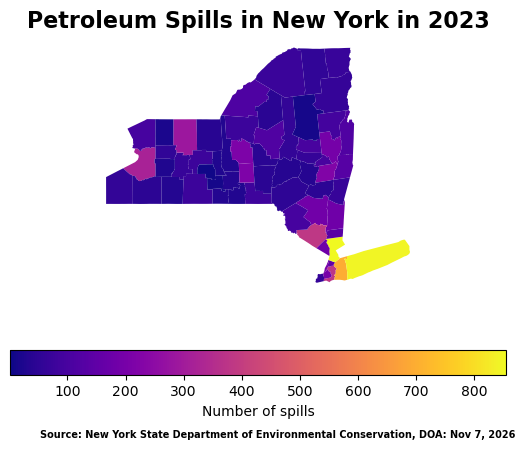

In [158]:
# FINAL CODE

# Import libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

# Import data
file_path1 = "data/Spill_Incidents_20261104.csv"
spills = pd.read_csv(file_path1)
file_path2 = "data/tl_2026_us_county/tl_2026_us_county.shp"
counties = gpd.read_file(file_path2)

## Data cleaning
# Rename column names
spills.rename(columns={"Material Family": "material_family", "Spill Date": "spill_date"}, inplace=True)
# Change spill_data column data type
spills['spill_date'] = pd.to_datetime(spills['spill_date'], format = "%m/%d/%Y")
# Choose spills only from 2023
petr_23 = spills[(spills['spill_date'].dt.year == 2023) & (spills['material_family'] == 'Petroleum')]

# Create spills_per_county data frame
spills_per_county = petr_23[['County', 'Spill Number']].drop_duplicates()
spills_per_county = spills_per_county['County'].value_counts().reset_index(name='n_spills')
spills_per_county.columns = ["county", "n_spills"]

# Filter to New York counties
counties = counties.rename(columns={"NAME": "county_name", "STATEFP": "state_fips",
                                    "COUNTYFP": "county_fips"})
ny_counties = counties[counties['state_fips'] == "36"]

# Add number of spills to New York counties data
spills_per_county.at[29, 'county'] = 'St. Lawrence'
ny_counties = ny_counties.rename(columns={'county_name': 'county'})
ny_spills = pd.merge(ny_counties, spills_per_county, how='inner', on='county')

# Add back dropped rows from merge
dropped_rows = spills_per_county.loc[[61, 63, 64, 65]]
ny_spills = pd.concat([ny_spills, dropped_rows], ignore_index=True)

# Add spills from Tuscarora and Onondaga Indian Reservations
ny_spills.at[31, 'n_spills'] = 98
ny_spills.at[33, 'n_spills'] = 215

# Initialize empty figure and axes
fig, ax = plt.subplots()

# Plot NY Petroleum spills
ny_spills.plot(ax=ax,column="n_spills", legend = True, cmap='plasma',
              legend_kwds={"label": "Number of spills", "orientation": "horizontal"})

ax.set_title("Petroleum Spills in New York in 2023", fontsize=16, fontweight="bold")
ax.set_axis_off()
ax.text(
    x=-81.5,
    y=37.5,
    s="Source: New York State Department of Environmental Conservation, DOA: Nov 7, 2026",
    fontsize=7,
    color="black",
    weight="bold",
)
# Display figure
plt.show()

## 1. File management
a. Any data you download should go in the `data/` folder of your `eds220-hwk3` repository. For example, after downloading both datasets, your repository should look like this:

```
eds220-hwk3/
├── data/
│   ├── q5d_df.csv
│   ├── Spill_Incidents_20261027.csv
│   └── tl_2026_us_county/
│       ├── tl_2026_us_county.cpg
│       ├── tl_2026_us_county.dbf
│       ├── tl_2026_us_county.prj
│       ├── tl_2026_us_county.shp
│       └── ... (other files from the shapefile)
├── tests/
├── .gitignore
├── LICENSE
├── README.md
└── hwk3-task2-spills.ipynb
```

The date in the name of the spills file may be different, depending on when you download it. `data/q5d_df.csv` is already in the repository and is used by the autograder tests, so do not delete or move it.

**IMPORTANT: Do not commit your data!**

The datasets we'll be working with are large and will most likely jam your commit history if git does not ignore them.

b. Add the relative path of each dataset you downloaded to your `.gitignore` file. For example, to ignore the folder containing the shapefile, add `data/tl_2026_us_county/` to the `.gitignore`.

c. Commit and push your changes to the `.gitignore`.

d. Run `git status` and verify that none of your data is being tracked by git.

## 2. Datasets description
- Read the metadata for both datasets and write a brief description about each one. Indicate the data sources and date of access.

## 3. Import libraries

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

## 4. Import data 
In the next cell:

- Import the NY spills data as a variable named `spills`. 
- Import the US counties data as a variable named `counties`.

If you are using file paths to access the data, these should be constructed using the `os` package.

In [12]:
file_path1 = "data/Spill_Incidents_20261104.csv"
spills = pd.read_csv(file_path1)


file_path2 = "data/tl_2026_us_county/tl_2026_us_county.shp"
counties = gpd.read_file(file_path2)

<!-- BEGIN QUESTION -->

## 5. Prepare spills data

This section refers to the `spills` dataframe. 
Check the outputs carefully, they will give you information you will need to use in the next exercises.

### 5.A. Exploration

In the next cells:

a. Check the dataframe's head

b. Check the data types of the columns

c. Check the unique values in the `material_family` column

d. Check the unique values in the `county` column

e. Insert a markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells for preliminary data exploration.

_Type your answer here, replacing this text._

In [7]:
#a. Check the dataframe's head
spills.head(20)

,Spill Number,Program Facility Name,Street 1,Street 2,Locality,County,ZIP Code,SWIS Code,DEC Region,Spill Date,Received Date,Contributing Factor,Waterbody,Source,Close Date,Material Name,Material Family,Quantity,Units,Recovered
0,107132,MH 864,RT 119/MILLWOOD RD,NaN,ELMSFORD,Westchester,NaN,6000,3,10/10/2001,10/10/2001,Unknown,NaN,Unknown,10/15/2001,unknown material,Other,10,Gallons,0
1,405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,08/21/2004,08/21/2004,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,NaN,0
2,405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,08/21/2004,08/21/2004,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,Pounds,0
3,204667,POLE 16091,GRACE AVE/BURKE AVE,NaN,BRONX,Bronx,NaN,301,2,08/02/2002,08/02/2002,Equipment Failure,NaN,Commercial/Industrial,10/28/2002,transformer oil,Petroleum,1,Gallons,0
4,210559,POLE ON,FERDALE LOMIS RD / RT 52,NaN,LIBERTY,Sullivan,NaN,5336,3,01/20/2003,01/20/2003,Traffic Accident,NaN,Commercial/Industrial,01/22/2003,transformer oil,Petroleum,6,Gallons,6
5,311484,PRIVATE RESIDENCE,6568 GLEN HAVEN RD,NaN,SCOTT,Cortland,NaN,1238,7,01/11/2004,01/11/2004,Equipment Failure,NaN,Private Dwelling,08/25/2004,#2 fuel oil,Petroleum,75,Gallons,0
6,104307,149TH RD,"183RD ST, 149TH AV& 149RD",NaN,QUEENS,Queens,NaN,4101,2,07/23/2001,07/23/2001,Abandoned Drums,NaN,Unknown,08/01/2001,unknown material,Other,0,Gallons,0
7,160046,ABANDONED DRUMS,BAKER SCHOOL HOUSE ROAD,NaN,SOLON,Cortland,NaN,1200,7,11/23/2001,11/23/2001,Abandoned Drums,NaN,Unknown,05/14/2002,unknown material,Other,0,Gallons,0
8,9606869,AMSTERDAM AVE,WEST 79 TH STREET,NaN,NYC,New York,NaN,3101,2,08/28/1996,08/28/1996,Traffic Accident,NaN,Commercial Vehicle,08/29/1996,antifreeze,Other,2,Gallons,2
9,312198,APARTMENT BUILDING,4 SOUTH SIDE TERRACE APAR,NaN,NEW PALTZ,Ulster,NaN,5638,3,02/02/2004,02/02/2004,Tank Failure,NaN,Commercial/Industrial,04/05/2004,#2 fuel oil,Petroleum,0,Pounds,0


In [37]:
#b. Check the data types of the columns
spills.dtypes

Spill Number              int64
Program Facility Name    object
Street 1                 object
Street 2                 object
Locality                 object
County                   object
ZIP Code                 object
SWIS Code                 int64
DEC Region                int64
Spill Date               object
Received Date            object
Contributing Factor      object
Waterbody                object
Source                   object
Close Date               object
Material Name            object
Material Family          object
Quantity                 object
Units                    object
Recovered                object
dtype: object

In [81]:
#c. Check the unique values in the `material_family` column
spills['Material Family'].unique()

array(['Other', 'Petroleum', 'Hazardous Material', 'Oxygenates'],
      dtype=object)

In [82]:
#d. Check the unique values in the `county` column
spills['County'].unique()

array(['Westchester', 'Queens', 'Bronx', 'Sullivan', 'Cortland',
       'New York', 'Ulster', 'Kings', 'Orange', 'Dutchess', 'Onondaga',
       'Saratoga', 'Cayuga', 'Oswego', 'Warren', 'Niagara', 'Rockland',
       'Nassau', 'Jefferson', 'Schenectady', 'Albany', 'Monroe',
       'Schuyler', 'St Lawrence', 'Richmond', 'Clinton', 'Lewis', 'Essex',
       'Chenango', 'Erie', 'Livingston', 'Oneida', 'Wayne', 'Suffolk',
       'Orleans', 'Ontario', 'Genesee', 'Otsego', 'Tompkins', 'Madison',
       'Chemung', 'Seneca', 'Broome', 'Hamilton', 'Washington', 'Steuben',
       'Rensselaer', 'Franklin', 'Columbia', 'Fulton', 'Herkimer',
       'Schoharie', 'Montgomery', 'Putnam', 'Delaware',
       'New Jersey - Region 2', 'Tioga', 'Chautauqua', 'Cattaraugus',
       'Wyoming', 'Yates', 'Greene', 'Pennsylvania - Region 9',
       'Allegany', 'New Jersey - Region 3 (N)',
       'Cattaraugus Indian Reservation', 'Connecticut - Region 3 (T)',
       'New Jersey - Region 3 (T)', 'Canada - Region 6',

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.B. Cleaning
a. Simplify column names as needed.

In [13]:
spills.rename(columns={"Material Family": "material_family", "Spill Date": "spill_date"}, inplace=True)

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Update column data types as needed.

In [14]:
#08/21/2004   MM/DD/YYYY
spills['spill_date'] = pd.to_datetime(spills['spill_date'], format = "%m/%d/%Y")

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.C. Data selection

a. Select data about petroleum spills that took place between January 1 and December 31, 2023 (including both dates). Store it in a variable named `petr_23`. The data selection should occur in a single line. You may add cells as needed.

In [15]:
petr_23 = spills[(spills['spill_date'].dt.year == 2023) & (spills['material_family'] == 'Petroleum')]

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use `print()` and f-strings to print a message verifying that `petr_23` only has data for 2023 and from January through December.
HINT: if you converted the `spill_date` column to datetime, you can use `petr_23['spill_date'].dt.year.unique()`.

In [16]:
petr_23['spill_date'].dt.year.unique()
print(f"What years are in petr_23? {petr_23['spill_date'].dt.year.unique()}")

What years are in petr_23? [2023]


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Write tests using `assert` to verify that `petr_23` only has data for petroleum spills.

In [17]:
assert petr_23['material_family'].unique() == 'Petroleum'

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Use `print()` and f-strings to print the number of rows in `petr_23` and the number of unique spills (use the `spill_number` column). Are these numbers the same? In the next markdown cell, explain why this might be the case. Use complete sentences. You may use additional cells to explore the data if needed.

The length of petr_23 is greater because there are duplicate of the same spill in the same county, adding rows that refer to the same spill.

In [153]:
print(f"Number of unique spills in petr_23: {petr_23['Spill Number'].unique().shape[0]}")
print(f"Length of rows in petr_23: {petr_23.shape[0]}")

Number of unique spills in petr_23: 8228
Length of rows in petr_23: 8468


<!-- END QUESTION -->

### 5.D. Data aggregation

Create new dataframe named `spills_per_county` with the number of petroleum spills per county from January to December 2023.

As you found in exercise 5.C.d, a spill can appear in more than one row. Make sure you count each spill only once. HINT: `nunique()`.

The resulting `spills_per_county` dataframe must be as follows:

- Index: integer numbers starting from 0
- Two columns only.
- Column one: county names, column name = `county`
- Column two: number of petroleum spills per county in 2023, column name = `n_spills`

You may add cells if needed for your data wrangling.

In [19]:
spills_per_county = petr_23[['County', 'Spill Number']].drop_duplicates()
spills_per_county = spills_per_county['County'].value_counts().reset_index(name='n_spills')
spills_per_county.columns = ["county", "n_spills"]
spills_per_county

,county,n_spills
0,Westchester,855
1,Suffolk,845
2,Nassau,698
3,Orange,382
4,Queens,380
...,...,...
61,New Jersey - Region 2,7
62,Yates,7
63,Tuscarora Indian Reservation,2
64,Onondaga Indian Reservation,1


In [20]:
grader.check("q5d")

q5d results: All test cases passed!

<!-- BEGIN QUESTION -->

## 6. Prepare counties data

This section refers to the `counties` geo-dataframe. 
Check the outputs carefully, they will give you context about the next exercises.

### 6.A. Exploration

In the next cells:

a. Check the geo-dataframe's head

b. Check the data types of the columns

c. Check the geo-dataframe's CRS

d. Plot the geo-dataframe

e. Use the next markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells of preliminary data exploration.

_Type your answer here, replacing this text._

In [21]:
# a
counties.head()

,STATEFP,COUNTYFP,COUNTYNS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,CSAFP,CBSAFP,METDIVFP,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,12,009,00295749,12009,0500000US12009,Brevard,Brevard County,06,H1,G4020,None,37340,None,A,2628767922,1403935652,+28.2983112,-080.7003334,"POLYGON ((-80.98725 28.61300, -80.98674 28.613..."
1,06,055,00277292,06055,0500000US06055,Napa,Napa County,06,H1,G4020,488,34900,None,A,1947608455,104442639,+38.5073502,-122.3259960,"POLYGON ((-122.10363 38.51216, -122.10365 38.5..."
2,18,065,00450359,18065,0500000US18065,Henry,Henry County,06,H1,G4020,294,35220,None,A,1014957933,7652087,+39.9252934,-085.3991588,"POLYGON ((-85.31955 39.78736, -85.32016 39.787..."
3,35,029,00933057,35029,0500000US35029,Luna,Luna County,06,H1,G4020,None,19700,None,A,7679773747,433660,+32.1845231,-107.7471911,"POLYGON ((-108.22982 32.20878, -108.22981 32.2..."
4,10,001,00217271,10001,0500000US10001,Kent,Kent County,06,H1,G4020,428,20100,None,A,1517891100,549776927,+39.0970884,-075.5029819,"POLYGON ((-75.31622 39.24531, -75.31308 39.241..."


In [22]:
# b
counties.dtypes

# STATEFP = State FIPS code
# COUNTYFP = County FIPS code
# COUNTYNS = County NS code
# NAME = County name

STATEFP       object
COUNTYFP      object
COUNTYNS      object
GEOID         object
GEOIDFQ       object
NAME          object
NAMELSAD      object
LSAD          object
CLASSFP       object
MTFCC         object
CSAFP         object
CBSAFP        object
METDIVFP      object
FUNCSTAT      object
ALAND          int64
AWATER         int64
INTPTLAT      object
INTPTLON      object
geometry    geometry
dtype: object

In [23]:
# c
counties.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

In [24]:
# d
fig, ax = plt.subplots()
counties.plot(ax=ax)

ax.set_xlim(-179.231086, -60)
ax.set_ylim(10, 71.439786)

plt.show()

<Figure size 640x480 with 1 Axes>

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.B. Cleaning

Simplify column names as needed.

In [25]:
counties = counties.rename(columns={"NAME": "county_name", "STATEFP": "state_fips",
                                    "COUNTYFP": "county_fips"})

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.C. Data selection

Select all the counties for the state of New York in a new variable `ny_counties` and plot them (you may need to look at the metadata).

In [26]:
ny_counties = counties[counties['state_fips'] == "36"]

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 7 Merging

The goal of this section is to create a single dataframe with the number of spills per county and the corresponding geometries for each county.

### 7.A. Explore data

In the next cells:

a. Print the names of counties in `ny_counties`, without repetition.


In [27]:
ny_counties = ny_counties.sort_values(by="county_name")
counties_geo_list = ny_counties['county_name'].to_list()
print(ny_counties['county_name'].to_list())

['Albany', 'Allegany', 'Bronx', 'Broome', 'Cattaraugus', 'Cayuga', 'Chautauqua', 'Chemung', 'Chenango', 'Clinton', 'Columbia', 'Cortland', 'Delaware', 'Dutchess', 'Erie', 'Essex', 'Franklin', 'Fulton', 'Genesee', 'Greene', 'Hamilton', 'Herkimer', 'Jefferson', 'Kings', 'Lewis', 'Livingston', 'Madison', 'Monroe', 'Montgomery', 'Nassau', 'New York', 'Niagara', 'Oneida', 'Onondaga', 'Ontario', 'Orange', 'Orleans', 'Oswego', 'Otsego', 'Putnam', 'Queens', 'Rensselaer', 'Richmond', 'Rockland', 'Saratoga', 'Schenectady', 'Schoharie', 'Schuyler', 'Seneca', 'St. Lawrence', 'Steuben', 'Suffolk', 'Sullivan', 'Tioga', 'Tompkins', 'Ulster', 'Warren', 'Washington', 'Wayne', 'Westchester', 'Wyoming', 'Yates']


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Print the names of counties in `spills_per_county`, without repetition. Examine the differences in the outputs.

In [28]:
sorted_spills_per_county = spills_per_county.sort_values(by="county")
counties_spill_list = sorted_spills_per_county['county'].to_list()
print(sorted_spills_per_county['county'].to_list())

['Albany', 'Allegany', 'Bronx', 'Broome', 'Cattaraugus', 'Cayuga', 'Chautauqua', 'Chemung', 'Chenango', 'Clinton', 'Columbia', 'Cortland', 'Delaware', 'Dutchess', 'Erie', 'Essex', 'Franklin', 'Fulton', 'Genesee', 'Greene', 'Hamilton', 'Herkimer', 'Jefferson', 'Kings', 'Lewis', 'Livingston', 'Madison', 'Monroe', 'Montgomery', 'Nassau', 'New Jersey - Region 2', 'New York', 'Niagara', 'Oneida', 'Onondaga', 'Onondaga Indian Reservation', 'Ontario', 'Orange', 'Orleans', 'Oswego', 'Otsego', 'Pennsylvania - Region 3', 'Putnam', 'Queens', 'Rensselaer', 'Richmond', 'Rockland', 'Saratoga', 'Schenectady', 'Schoharie', 'Schuyler', 'Seneca', 'St Lawrence', 'Steuben', 'Suffolk', 'Sullivan', 'Tioga', 'Tompkins', 'Tuscarora Indian Reservation', 'Ulster', 'Warren', 'Washington', 'Wayne', 'Westchester', 'Wyoming', 'Yates']


<!-- END QUESTION -->



c. Which are the county names that are in `spills_per_county`, but not in `ny_counties`? Your answer should be a list of strings
HINT: You can use the `numpy` function [`setdiff1d()`](https://numpy.org/doc/stable/reference/generated/numpy.setdiff1d.html), pay attention to the example in the documentation. Store your answer in the `diff_names` variable. 


In [29]:
diff_names_spills = np.setdiff1d(counties_spill_list, counties_geo_list)
diff_names_spills

array(['New Jersey - Region 2', 'Onondaga Indian Reservation',
       'Pennsylvania - Region 3', 'St Lawrence',
       'Tuscarora Indian Reservation'], dtype='<U28')

In [30]:
grader.check("7Ac")

7Ac results: All test cases passed!

d. Which are the county names that are in `ny_counties`, but not in `spills_per_county`? Your answer should be a list of a string/strings.


In [31]:
diff_names_ny = np.setdiff1d(counties_geo_list, counties_spill_list)
diff_names_ny

array(['St. Lawrence'], dtype='<U12')

In [32]:
grader.check("7Ad")

7Ad results: All test cases passed!

e. What is the number of spills in 'Tuscarora Indian Reservation' and in 'Onondaga Indian Reservation'?


In [40]:
# e.
spills_per_county[(spills_per_county['county'] == 'Tuscarora Indian Reservation') | (spills_per_county['county'] == 'Onondaga Indian Reservation')]

# Tuscarora has 2 spills and Onondaga has 1 spill

,county,n_spills
63,Tuscarora Indian Reservation,2
64,Onondaga Indian Reservation,1


### 7.B. Data updates

In the next cell, update 'St Lawrence' to 'St. Lawrence' in the `spills_per_county` data frame. Verify the update was successful with an assert test. 


In [180]:
spills_per_county.at[29, 'county'] = 'St. Lawrence'
assert spills_per_county.at[29, 'county'] == 'St. Lawrence'

### 7.C. Merge

In the following cells:

a. Use this cell to make any other updates needed for making an inner join of the `spills_per_county` and `ny_counties`. HINT: [`pd.merge`](https://pandas.pydata.org/pandas-docs/version/2.3/reference/api/pandas.merge.html)


In [52]:
# a 
ny_counties['county_name']
ny_counties = ny_counties.rename(columns={'county_name': 'county'})
pd.merge(spills_per_county, ny_counties, how='inner', on='county')

,county,n_spills,state_fips,county_fips,COUNTYNS,GEOID,GEOIDFQ,NAMELSAD,LSAD,CLASSFP,MTFCC,CSAFP,CBSAFP,METDIVFP,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,Westchester,855,36,119,00974157,36119,0500000US36119,Westchester County,06,H1,G4020,408,35620,35614,A,1115811923,179391712,+41.1526862,-073.7457526,"POLYGON ((-73.65762 40.98550, -73.65739 40.985..."
1,Suffolk,845,36,103,00974149,36103,0500000US36103,Suffolk County,06,H1,G4020,408,35620,35004,A,2359209021,3787486264,+40.9435540,-072.6922183,"POLYGON ((-71.80938 41.20323, -71.79115 41.184..."
2,Nassau,698,36,059,00974128,36059,0500000US36059,Nassau County,06,H1,G4020,408,35620,35004,A,736965427,437285877,+40.7295039,-073.5894030,"POLYGON ((-73.78019 40.82640, -73.77498 40.830..."
3,Orange,382,36,071,00974134,36071,0500000US36071,Orange County,06,H1,G4020,408,28880,None,A,2103273918,67952543,+41.4024096,-074.3062522,"POLYGON ((-74.24491 41.60376, -74.24456 41.603..."
4,Queens,380,36,081,00974139,36081,0500000US36081,Queens County,06,H6,G4020,408,35620,35614,C,281594058,188444380,+40.6546581,-073.8412089,"POLYGON ((-74.03813 40.53829, -74.03749 40.542..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57,Seneca,27,36,099,00974147,36099,0500000US36099,Seneca County,06,H1,G4020,464,42900,None,A,838377561,172813845,+42.7822943,-076.8270880,"POLYGON ((-76.96393 43.01284, -76.96393 43.012..."
58,Orleans,19,36,073,00974135,36073,0500000US36073,Orleans County,06,H1,G4020,464,40380,None,A,1013364732,1103744015,+43.3388986,-078.2110958,"POLYGON ((-77.99691 43.21776, -77.99693 43.216..."
59,Schuyler,13,36,097,00974146,36097,0500000US36097,Schuyler County,06,H1,G4020,None,None,None,A,850405401,36246372,+42.4197755,-076.9386030,"POLYGON ((-77.10711 42.48377, -77.10684 42.483..."
60,Hamilton,12,36,041,00974119,36041,0500000US36041,Hamilton County,06,H1,G4020,None,None,None,A,4447989317,234204424,+43.6578786,-074.5024556,"POLYGON ((-74.20976 43.24926, -74.21149 43.249..."


b. Store the inner join of the `spills_per_county` and `ny_counties` dataframes in a new variable named `ny_spills`.


In [111]:
ny_spills = pd.merge(ny_counties, spills_per_county, how='inner', on='county')
ny_spills.head(5)

,state_fips,county_fips,COUNTYNS,GEOID,GEOIDFQ,county,NAMELSAD,LSAD,CLASSFP,MTFCC,CSAFP,CBSAFP,METDIVFP,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry,n_spills
0,36,001,00974099,36001,0500000US36001,Albany,Albany County,06,H1,G4020,104,10580,None,A,1354273428,26971923,+42.5882401,-073.9740095,"POLYGON ((-73.96379 42.44162, -73.96666 42.441...",224
1,36,003,00974100,36003,0500000US36003,Allegany,Allegany County,06,H1,G4020,None,None,None,A,2666410162,12989705,+42.2478532,-078.0261531,"POLYGON ((-78.04342 42.51846, -78.04326 42.518...",32
2,36,005,00974101,36005,0500000US36005,Bronx,Bronx County,06,H6,G4020,408,35620,35614,C,109301867,39287123,+40.8487111,-073.8529390,"POLYGON ((-73.93381 40.88221, -73.93365 40.882...",152
3,36,007,00974102,36007,0500000US36007,Broome,Broome County,06,H1,G4020,None,13780,None,A,1827626584,25078248,+42.1619773,-075.8302833,"POLYGON ((-75.74223 41.99805, -75.75080 41.997...",80
4,36,009,00974103,36009,0500000US36009,Cattaraugus,Cattaraugus County,06,H1,G4020,160,36460,None,A,3388177044,36783591,+42.2390986,-078.6623320,"POLYGON ((-78.69725 41.99867, -78.69881 41.998...",45


<!-- BEGIN QUESTION -->

c. An inner join only keeps the rows whose `county` appears in both dataframes, and it does not warn you about the rows it drops. Which records from `spills_per_county` were dropped by the inner join, and how many spills did each one have? Add the cells you need to find the dropped records.

In [112]:
print(spills_per_county.shape)
print(ny_spills.shape)

(66, 2)
(62, 20)


In [113]:
ny_spills_list = ny_spills['county'].to_list()
spills_per_county_list = spills_per_county['county'].to_list()
np.setdiff1d(spills_per_county_list, ny_spills_list)
# All regions not added:
# 'New Jersey - Region 2', 'Onondaga Indian Reservation',
# 'Pennsylvania - Region 3', 'Tuscarora Indian Reservation'

array(['New Jersey - Region 2', 'Onondaga Indian Reservation',
       'Pennsylvania - Region 3', 'Tuscarora Indian Reservation'],
      dtype='<U28')

In [114]:
spills_per_county[(spills_per_county['county'] == 'New Jersey - Region 2')
    | (spills_per_county['county'] == 'Onondaga Indian Reservation')
    | (spills_per_county['county'] == 'Pennsylvania - Region 3')
    | (spills_per_county['county'] == 'Tuscarora Indian Reservation')]

,county,n_spills
61,New Jersey - Region 2,7
63,Tuscarora Indian Reservation,2
64,Onondaga Indian Reservation,1
65,Pennsylvania - Region 3,1


In [115]:
dropped_rows = spills_per_county.loc[[61, 63, 64, 65]]
ny_spills = pd.concat([ny_spills, dropped_rows], ignore_index=True)

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Does dropping these records affect the map or the information we will report? Write your answer in the following markdown cell.

Dropping this information will not affect our maps or information we report because there
is no map geometry for these four areas are not recognized by the Census Bureau, so we can't
represent these areas in our maps.

<!-- END QUESTION -->


From our previous exploration we know that Tuscarora Indian Reservation and Onondaga Indian Reservation will not be in the join. Tuscarora Indian Reservation is located within Niagara county and Onondaga Indian Reservation is located within Onondaga county. 

e. Since the reservations do not appear in the `ny_counties` dataframe, add the Tuscarora Indian Reservation spills to Niagara county and the Onondaga Indian Reservation spills to Onondaga county in `ny_spills`. We will add a note about this in our final map, and we will reflect on this choice in exercise 8.b. Add the cells you need to make this update **and** verify that the dataframe was updated.

In [116]:
# Tuscarora has 2 spills
# Onondaga has 1 spill
ny_spills[ny_spills['county'] == 'Niagara']
# Niagara is row 31, with 97 spills
ny_spills[ny_spills['county'] == 'Onondaga']
# Onondaga is row 33, with 214 spills

ny_spills.at[31, 'n_spills'] = 98
ny_spills.at[33, 'n_spills'] = 215
ny_spills[(ny_spills['county'] == 'Niagara') | (ny_spills['county'] == 'Onondaga')]

,state_fips,county_fips,COUNTYNS,GEOID,GEOIDFQ,county,NAMELSAD,LSAD,CLASSFP,MTFCC,CSAFP,CBSAFP,METDIVFP,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry,n_spills
31,36,063,00974130,36063,0500000US36063,Niagara,Niagara County,06,H1,G4020,160,15380,None,A,1.352876e+09,1.598772e+09,+43.2726719,-078.8129431,"POLYGON ((-78.49165 43.08396, -78.49179 43.084...",98
33,36,067,00974132,36067,0500000US36067,Onondaga,Onondaga County,06,H1,G4020,532,45060,None,A,2.016028e+09,7.051284e+07,+43.0065163,-076.1961336,"POLYGON ((-76.08017 42.78160, -76.08018 42.780...",215


## 8. Map
a. Create a choropleth map of the number of petroleum spills per county in the state of New York in 2023. 
Your map should be polished and have (at least) the following updates:
- a legend indicating the number of spills
- an updated color map
- a title 
- no axis
- an annotation with the data source (New York State Department of Environmental Conservation) and date of access



In [119]:
ny_spills.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

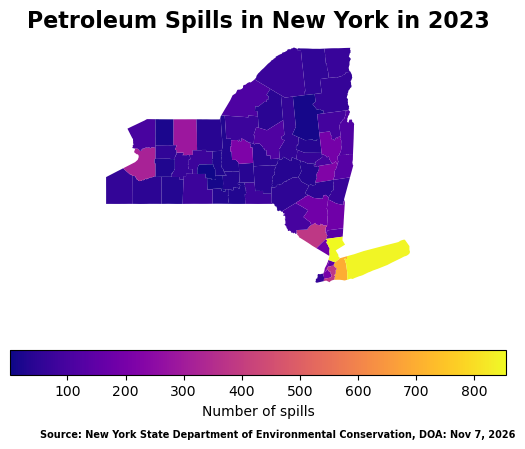

In [146]:
# Initialize empty figure and axes
fig, ax = plt.subplots()

# Add polygons plot to our figure's axes
ny_spills.plot(ax=ax,column="n_spills", legend = True, cmap='plasma',
              legend_kwds={"label": "Number of spills", "orientation": "horizontal"})

ax.set_title("Petroleum Spills in New York in 2023", fontsize=16, fontweight="bold")
ax.set_axis_off()
ax.text(
    x=-81.5,
    y=37.5,
    s="Source: New York State Department of Environmental Conservation, DOA: Nov 7, 2026",
    fontsize=7,
    color="black",
    weight="bold",
)
# Display figure
plt.show()

b. Write a description of how the map was created, including key takeaways. If you need to do additional data analysis to include relevant information from the data, you may include additional cells here.

In your description, also reflect on how we handled the spills reported in the Tuscarora and Onondaga Indian Reservations (exercise 7.C.e) in terms of data governance and the CARE Principles for Indigenous Data Governance from Task 1.

This map was created using data from the New York State Department of Environmental Conservation and census tracks from the Census Bureau. Data was wrangled in python and number of spills was grouped on a county level. Key takeaways from creating this map is that petroleum spills seem to be highest near the southeast Long Island part of New York. Looking more into this region, this

Four counties that were present in the Environmental Conservation data were not present in the Census Bureau, New Jersey Region 2, Pennsylvania Region 3, the Onondaga Indian Reservation and Tuscarora Indian Reservation. The spills happening in the Onondaga and Tuscarora Indian Reservation were grouped into Onondaga county and Niagara county respectfully. This was done in accordance with CARE principles it responsibly represents communities not officially recognized by the bureau, collectively benefits data by including indigenous people within larger datasets, recognizes the rights of who owns the land the petroleum was spilled on, and is ethical for showing where spills happen and achieving justice for indigenous communities.

## Complete workflow

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the choropleth map of the number of petroleum spills per county in the state of New York in 2023. The only output of this cell should be the choropleth map  you produced in the previous exercise. Further guidance on what to include in this final workflow is in the assignment rubric.